# Heading & Error Calculation & Visualization

In [4]:
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from ipywidgets import interact

def getTargetHeading(e, n):
    targetHeading_rad = np.arctan2(e,n) + np.pi
    targetHeading_deg = targetHeading_rad * 180 / np.pi
    return targetHeading_deg

def getThetaErr(actualHeading_deg, targetHeading_deg):
    error_deg = actualHeading_deg - targetHeading_deg 
    if error_deg > 180:
        error_deg -= 360
    elif error_deg < -180:
        error_deg += 360
    return error_deg

In [ ]:
### INPUTS ######
# @interact(posEast=(10,2000,2))
# @interact(posNorth=(10,2000,2))
# @interact(heading_deg = (0,360,1))
#################

def solve_and_visualize_heading(posEast, posNorth, heading_deg):
    p = (posEast,posNorth)
    norm = np.sqrt(p[0]**2 + p[1]**2)
    targetHeading_deg = getTargetHeading(p[0], p[1])
    thetaErr = getThetaErr(heading_deg, targetHeading_deg)

    print("\n..:: HEADING & ERROR CALCULATION ::..")
    print(f"Current Heading\t: {heading_deg:.2f} degrees")
    print(f"Target Heading\t: {targetHeading_deg:.2f} degrees")
    print(f"Error\t\t: {thetaErr:.2f} degrees")
    print(f"Distance\t: {norm:.2f} m\n")


    heading_rad = heading_deg * np.pi / 180
    unit_step = (np.sin(heading_rad), np.cos(heading_rad))
    step = [u * norm*0.4 for u in unit_step]

    plt.plot(p[0], p[1], 'ko', label='Current Position') # current position
    # plt.plot(0,0, 'bo', markerfacecolor='none', markeredgewidth=2, label='Target (Launch Pad)')
    plt.plot(0,0, 'bx', markersize=10, markeredgewidth=2, label='Target (Launch Pad)')

    ## plot heading and desired heading
    X, Y = p # Tail coordinates
    U, V = unit_step  # Direction vector
    plt.quiver(X, Y, U, V, scale=10, angles='xy', color='m', width=0.005, 
            headwidth=3, headlength=6, headaxislength=6, alpha=0.6, label='Heading')

    X, Y = p # Tail coordinates
    U, V = -p[0]/norm, -p[1]/norm  # Direction vector
    plt.quiver(X, Y, U, V, scale=10, angles='xy', color='b', width=0.005, 
            headwidth=3, headlength=6, headaxislength=6, alpha=0.6, label='Desired Heading')

    plt.title("Calculation of ARES Desired Heading and Error")
    plt.xlabel("East (m)")
    plt.ylabel("North (m)")
    lim = norm*1.5
    plt.xlim([-lim, lim])
    plt.ylim([-lim, lim])
    plt.grid(True)
    plt.legend()
    plt.show()


..:: HEADING & ERROR CALCULATION ::..
Current Heading	: 300.00 degrees
Target Heading	: 104.04 degrees
Error		: -164.04 degrees
Distance	: 824.62 m



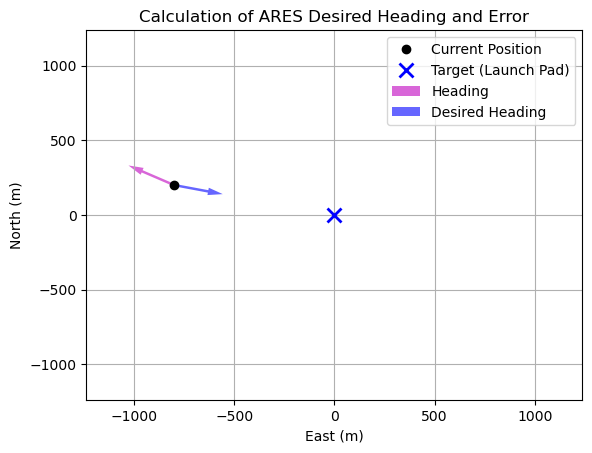

In [10]:
p = (-800, 200)
heading_deg = 300
norm = np.sqrt(p[0]**2 + p[1]**2)
targetHeading_deg = getTargetHeading(p[0], p[1])
thetaErr = getThetaErr(heading_deg, targetHeading_deg)

print("\n..:: HEADING & ERROR CALCULATION ::..")
print(f"Current Heading\t: {heading_deg:.2f} degrees")
print(f"Target Heading\t: {targetHeading_deg:.2f} degrees")
print(f"Error\t\t: {thetaErr:.2f} degrees")
print(f"Distance\t: {norm:.2f} m\n")


heading_rad = heading_deg * np.pi / 180
unit_step = (np.sin(heading_rad), np.cos(heading_rad))
step = [u * norm*0.4 for u in unit_step]

plt.plot(p[0], p[1], 'ko', label='Current Position') # current position
# plt.plot(0,0, 'bo', markerfacecolor='none', markeredgewidth=2, label='Target (Launch Pad)')
plt.plot(0,0, 'bx', markersize=10, markeredgewidth=2, label='Target (Launch Pad)')

## plot heading and desired heading
X, Y = p # Tail coordinates
U, V = unit_step  # Direction vector
plt.quiver(X, Y, U, V, scale=10, angles='xy', color='m', width=0.005, 
        headwidth=3, headlength=6, headaxislength=6, alpha=0.6, label='Heading')

X, Y = p # Tail coordinates
U, V = -p[0]/norm, -p[1]/norm  # Direction vector
plt.quiver(X, Y, U, V, scale=10, angles='xy', color='b', width=0.005, 
        headwidth=3, headlength=6, headaxislength=6, alpha=0.6, label='Desired Heading')

plt.title("Calculation of ARES Desired Heading and Error")
plt.xlabel("East (m)")
plt.ylabel("North (m)")
lim = norm*1.5
plt.xlim([-lim, lim])
plt.ylim([-lim, lim])
plt.grid(True)
plt.legend()
plt.show()